# Practice 2 — Train Your First Neural Network with PyTorch

**Estimated class time: ~120 minutes**

In Practice 1, we opened a neural network and watched a **forward pass**: input numbers went through layers and became an output number.

This notebook adds the missing part:

> **How do we create a network in a deep-learning library, feed data into it, let it learn, and then use it on a new input?**

We will build a small neural network **from scratch** for a synthetic binary-classification problem:

> Predict whether a student will **PASS** or **FAIL** a course.

The input features are:

1. attendance rate (%),
2. study hours per week,
3. midterm score (0–10).

The labels are generated by code so the notebook needs **no external dataset**.

### Learning goals

By the end, you should be able to:

- explain what PyTorch provides for deep learning;
- distinguish a **tensor**, a **dataset**, a **batch**, a **model**, a **loss function**, and an **optimizer**;
- define a small MLP using `torch.nn.Module`;
- check input/output shapes before training;
- feed batches of data to a model;
- understand the structure of a basic training loop;
- observe loss and accuracy while the model learns;
- switch from training mode to inference mode;
- make a prediction for a new student.

### Suggested 120-minute flow

| Time | Activity |
|---:|---|
| 0–10 min | PyTorch and tensors |
| 10–25 min | Generate and inspect synthetic student data |
| 25–40 min | Train/test split, normalization, Dataset and DataLoader |
| 40–60 min | Build the MLP and inspect its architecture |
| 60–90 min | Train the network and read the logs |
| 90–100 min | Evaluate on unseen data |
| 100–110 min | Inference on new students |
| 110–120 min | Exercises and experiments |

> This is a teaching dataset. It is designed to explain the mechanics of deep learning, not to make real academic decisions about students.

## 1. Setup — a deep-learning library

We will use **PyTorch**.

PyTorch gives us several useful building blocks:

- `torch.Tensor` — stores numerical data;
- `torch.nn` — neural-network layers and loss functions;
- `torch.optim` — optimization algorithms that update parameters;
- `Dataset` and `DataLoader` — organize data and provide mini-batches;
- automatic differentiation — computes gradients for us during training.

The code below checks the small set of packages used by this notebook. Google Colab normally already provides them, so the installation branch is usually skipped.

In [1]:
import importlib.util
import subprocess
import sys

required_packages = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "torch": "torch",
}

missing = [pip_name for module_name, pip_name in required_packages.items()
           if importlib.util.find_spec(module_name) is None]

if missing:
    print("Installing missing packages:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("Setup complete.")

Installing missing packages: ['torch']
Python: 3.12.4
PyTorch: 2.14.0+cpu
NumPy: 2.5.0
Setup complete.


### Reproducibility for a classroom notebook

Neural networks normally start from random parameters, and our synthetic data is random too. If every student gets completely different numbers, debugging becomes harder.

So we fix a **random seed**.

This does not mean every PyTorch program is perfectly reproducible across all hardware and all library versions. It simply removes major sources of randomness for this small CPU example.

In [9]:
SEED = 2026

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# CPU is intentional here: the network is tiny and this keeps the workshop simple.
device = torch.device("cpu")
print("Device:", device)

Device: cpu


## 2. First contact with tensors

A **tensor** is the main numerical object used by PyTorch.

For this course, you can initially think of it as a NumPy array that PyTorch knows how to use inside neural networks and automatic differentiation.

One student can be represented as three numbers:

```text
[attendance, study_hours, midterm_score]
```

In [10]:
student = torch.tensor([80.0, 6.0, 7.0], dtype=torch.float32)

print("Tensor:", student)
print("Shape:", student.shape)
print("Data type:", student.dtype)

Tensor: tensor([80.,  6.,  7.])
Shape: torch.Size([3])
Data type: torch.float32


The shape is `(3,)`: one vector containing three features.

For neural-network training, we usually process several samples together. A batch of four students therefore has shape:

```text
(4 students, 3 features)
```

In [11]:
batch_example = torch.tensor([
    [80.0, 6.0, 7.0],
    [55.0, 2.0, 4.0],
    [92.0, 8.0, 8.5],
    [70.0, 4.0, 5.5],
], dtype=torch.float32)

print(batch_example)
print("Batch shape:", batch_example.shape)

tensor([[80.0000,  6.0000,  7.0000],
        [55.0000,  2.0000,  4.0000],
        [92.0000,  8.0000,  8.5000],
        [70.0000,  4.0000,  5.5000]])
Batch shape: torch.Size([4, 3])


## 3. Generate a synthetic PASS / FAIL dataset

In a real project, labels come from observations: actual exam results, medical diagnoses, user behavior, images labeled by humans, and so on.

For this practice session, we generate both features and labels in code.

We will create **1,200 students**. The generator uses a hidden rule plus random noise. Students with stronger attendance, study time, and midterm performance are generally more likely to pass, but the relationship is not perfectly deterministic.

That noise is useful: real data rarely follows a perfectly clean rule.

**Important:** in real machine learning, we do not know the true hidden rule. The model must infer useful patterns from examples.

In [12]:
rng = np.random.default_rng(SEED)
N_STUDENTS = 1200

attendance = rng.uniform(45, 100, N_STUDENTS)                 # percent
study_hours = np.clip(rng.gamma(2.0, 2.5, N_STUDENTS), 0, 15) # hours/week
midterm_score = np.clip(rng.normal(5.5, 2.0, N_STUDENTS), 0, 10)

# A hidden rule used ONLY to generate teaching labels.
# It contains both linear effects and a small interaction effect.
readiness = (
    0.055 * (attendance - 70)
    + 0.38 * (midterm_score - 5)
    + 0.12 * (study_hours - 4)
    + 0.35 * ((attendance > 75) & (midterm_score > 5.5))
    - 0.25 * ((attendance < 60) & (study_hours < 3))
    + rng.normal(0, 0.9, N_STUDENTS)  # noise
)

passed = (readiness > 0).astype(np.float32)

student_df = pd.DataFrame({
    "attendance": attendance,
    "study_hours": study_hours,
    "midterm_score": midterm_score,
    "passed": passed.astype(int),
})

student_df.head(10)

,attendance,study_hours,midterm_score,passed
0,54.841415,2.887881,4.700206,0
1,80.195224,0.836803,6.326464,1
2,70.699762,5.439643,4.733278,1
3,65.377529,4.809402,8.193508,1
4,64.520453,5.746380,6.790036,1
5,88.478504,5.582276,6.230562,1
6,94.782911,4.993445,8.083892,1
7,54.754426,2.868429,3.085843,0
8,80.903164,3.689420,5.776035,1
9,61.406652,3.384328,7.077587,1


In [13]:
print("Dataset shape:", student_df.shape)
print("Pass rate: {:.1f}%".format(100 * student_df["passed"].mean()))
print("Fail rate: {:.1f}%".format(100 * (1 - student_df["passed"].mean())))

student_df.describe().round(2)

Dataset shape: (1200, 4)
Pass rate: 63.6%
Fail rate: 36.4%


,attendance,study_hours,midterm_score,passed
count,1200.00,1200.00,1200.00,1200.00
mean,73.41,4.89,5.55,0.64
std,15.76,3.32,1.98,0.48
min,45.08,0.04,0.00,0.00
25%,60.37,2.32,4.26,0.00
50%,74.22,4.20,5.60,1.00
75%,86.88,6.66,6.90,1.00
max,99.99,15.00,10.00,1.00


### A quick visual check

A visualization is not the model. It is a way for us to inspect whether the generated data roughly makes sense.

The plot below uses only two features at a time, so it cannot show the complete three-dimensional problem.

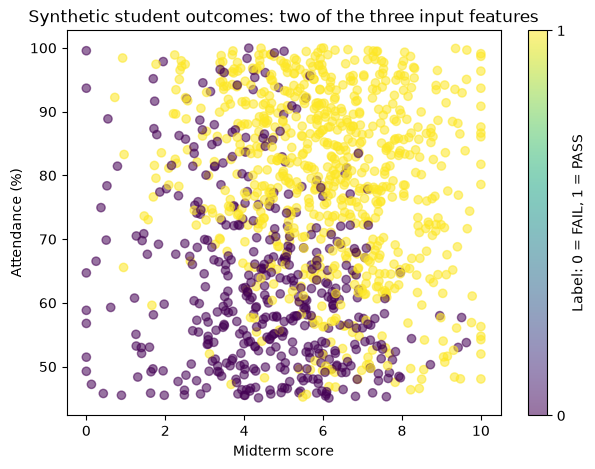

In [14]:
plt.figure(figsize=(7, 5))
scatter = plt.scatter(
    student_df["midterm_score"],
    student_df["attendance"],
    c=student_df["passed"],
    alpha=0.55,
)
plt.xlabel("Midterm score")
plt.ylabel("Attendance (%)")
plt.title("Synthetic student outcomes: two of the three input features")
plt.colorbar(scatter, ticks=[0, 1], label="Label: 0 = FAIL, 1 = PASS")
plt.show()

## 4. Separate features and labels

For supervised learning we need:

- `X`: the input features;
- `y`: the target labels.

For this binary task:

```text
y = 0  -> FAIL
y = 1  -> PASS
```

In [15]:
feature_names = ["attendance", "study_hours", "midterm_score"]

X = student_df[feature_names].to_numpy(dtype=np.float32)
y = student_df["passed"].to_numpy(dtype=np.float32).reshape(-1, 1)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("First X row:", X[0])
print("First y value:", y[0])

X shape: (1200, 3)
y shape: (1200, 1)
First X row: [54.841415  2.887881  4.700206]
First y value: [0.]


## 5. Split the data before normalization

We keep **20%** of the students as a test set.

The model will never use these test labels to update its weights. They represent unseen examples used after training.

A useful habit is:

> **split first, then compute preprocessing statistics from the training set only.**

If we use information from the test set while preparing the training data, we create a form of **data leakage**.

In [16]:
rng_split = np.random.default_rng(SEED)
indices = rng_split.permutation(len(X))

split_index = int(0.80 * len(X))
train_idx = indices[:split_index]
test_idx = indices[split_index:]

X_train_raw, X_test_raw = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

print("Training samples:", len(X_train_raw))
print("Test samples:", len(X_test_raw))

Training samples: 960
Test samples: 240


## 6. Normalize the input features

The three features have very different numeric ranges:

- attendance: roughly 45–100;
- study hours: roughly 0–15;
- midterm score: 0–10.

Neural networks often train more smoothly when input features have comparable scales.

We standardize each feature using the **training-set mean and standard deviation**:

$$
x_{scaled}=\frac{x-\mu_{train}}{\sigma_{train}}
$$

We then apply the same training statistics to the test set and future inputs.

In [17]:
train_mean = X_train_raw.mean(axis=0, keepdims=True)
train_std = X_train_raw.std(axis=0, keepdims=True)

X_train = (X_train_raw - train_mean) / train_std
X_test = (X_test_raw - train_mean) / train_std

normalization_table = pd.DataFrame({
    "feature": feature_names,
    "train_mean": train_mean.ravel(),
    "train_std": train_std.ravel(),
})
normalization_table.round(3)

,feature,train_mean,train_std
0,attendance,73.561996,15.522
1,study_hours,4.928000,3.325
2,midterm_score,5.515000,1.995


In [ ]:
print("Normalized training mean (approximately 0):", X_train.mean(axis=0).round(4))
print("Normalized training std  (approximately 1):", X_train.std(axis=0).round(4))

Normalized training mean (approximately 0): [ 0. -0. -0.]
Normalized training std  (approximately 1): [1. 1. 1.]


## 7. Convert the data to PyTorch and create mini-batches

`TensorDataset` pairs each feature vector with its label.

`DataLoader` then gives the training loop small **mini-batches** instead of the entire dataset at once.

For this notebook:

```text
batch size = 32
```

This means one training step usually processes 32 students.

In [18]:
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

BATCH_SIZE = 32
loader_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=loader_generator,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

first_X_batch, first_y_batch = next(iter(train_loader))
print("Feature batch shape:", first_X_batch.shape)
print("Label batch shape:", first_y_batch.shape)
print("First normalized student in this batch:", first_X_batch[0])
print("Its label:", first_y_batch[0])

Feature batch shape: torch.Size([32, 3])
Label batch shape: torch.Size([32, 1])
First normalized student in this batch: tensor([0.1585, 0.7341, 0.5756])
Its label: tensor([1.])


## 8. Design the network architecture

We will build a small **MLP (Multi-Layer Perceptron)**:

```text
3 input features
      |
Linear(3 -> 8)
      |
    ReLU
      |
Linear(8 -> 4)
      |
    ReLU
      |
Linear(4 -> 1)
      |
   one logit
```

The network is intentionally small. More layers or more neurons do **not** automatically mean a better model.

### Setup notes worth remembering

1. **Input size must match the number of features.** We have 3 features, so the first layer expects 3 values.
2. **Start small.** A tiny tabular problem does not need a huge network.
3. **Use nonlinear activations between linear layers.** Here we use ReLU.
4. **Binary classification needs one output value.** We will interpret it as a logit.
5. **Do not put Sigmoid inside this model when training with `BCEWithLogitsLoss`.** That loss combines the numerically stable sigmoid + binary cross-entropy calculation.
6. **Check shapes before training.** Shape errors are among the most common beginner mistakes.
7. The parameters start from a random initialization. We are **not using a pretrained model**.

In [19]:
class StudentPassMLP(nn.Module):
    def __init__(self, input_dim=3, hidden1=8, hidden2=4):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden1),
            nn.ReLU(),
            nn.Linear(hidden1, hidden2),
            nn.ReLU(),
            nn.Linear(hidden2, 1),
        )

    def forward(self, x):
        return self.network(x)


# Reset the seed immediately before model creation so initialization is predictable.
torch.manual_seed(SEED)
model = StudentPassMLP().to(device)

print(model)

StudentPassMLP(
  (network): Sequential(
    (0): Linear(in_features=3, out_features=8, bias=True)
    (1): ReLU()
    (2): Linear(in_features=8, out_features=4, bias=True)
    (3): ReLU()
    (4): Linear(in_features=4, out_features=1, bias=True)
  )
)


### Count the trainable parameters

Every weight and bias that has `requires_grad=True` can be updated during training.

For a linear layer with `in_features = a` and `out_features = b`:

$$
	ext{parameters}=a	imes b+b
$$

The final `+ b` is for the biases.

In [20]:
total_params = 0
for name, parameter in model.named_parameters():
    print(f"{name:25s} shape={tuple(parameter.shape)!s:10s} parameters={parameter.numel():3d}")
    total_params += parameter.numel()

print()
print("Total trainable parameters:", total_params)

network.0.weight          shape=(8, 3)     parameters= 24
network.0.bias            shape=(8,)       parameters=  8
network.2.weight          shape=(4, 8)     parameters= 32
network.2.bias            shape=(4,)       parameters=  4
network.4.weight          shape=(1, 4)     parameters=  4
network.4.bias            shape=(1,)       parameters=  1

Total trainable parameters: 73


## 9. Test one forward pass before training

Before writing a training loop, verify that:

- the model accepts the expected input shape;
- the output shape is correct;
- the values are finite.

The model has random parameters at this point, so its predictions are not meaningful yet.

In [21]:
model.eval()
with torch.inference_mode():
    sample_logits = model(first_X_batch[:5].to(device))
    sample_probabilities = torch.sigmoid(sample_logits)

print("Input shape:", first_X_batch[:5].shape)
print("Logit shape:", sample_logits.shape)
print()
print("Logits before training:")
print(sample_logits.squeeze())
print()
print("Probabilities before training:")
print(sample_probabilities.squeeze())
print()
print("True labels:")
print(first_y_batch[:5].squeeze())

Input shape: torch.Size([5, 3])
Logit shape: torch.Size([5, 1])

Logits before training:
tensor([-0.4326, -0.4641, -0.4357, -0.5241, -0.4357])

Probabilities before training:
tensor([0.3935, 0.3860, 0.3928, 0.3719, 0.3928])

True labels:
tensor([1., 0., 1., 0., 1.])


### What is a logit?

The last layer returns an unrestricted real number such as:

```text
-1.8, 0.2, 2.4, ...
```

That number is the **logit**.

For interpretation, Sigmoid converts a logit into a value between 0 and 1:

$$
p=\sigma(z)=\frac{1}{1+e^{-z}}
$$

We can read that value as the model's estimated probability of `PASS = 1`.

During training we feed the **raw logits** directly to `BCEWithLogitsLoss`.

## 10. Choose a loss function and optimizer

We now need two pieces:

### Loss function

`BCEWithLogitsLoss` measures how wrong the binary predictions are.

The training goal is not to directly "increase accuracy" at each line of code. The optimizer follows gradients that reduce the **loss**.

### Optimizer

We will use `Adam`, a common gradient-based optimizer.

The learning rate controls the update step size. For this small example we use:

```text
learning rate = 0.01
```

There is no universally correct learning rate. It is a hyperparameter that often needs experimentation.

In [22]:
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

print("Loss function:", loss_fn)
print("Optimizer:", optimizer.__class__.__name__)

Loss function: BCEWithLogitsLoss()
Optimizer: Adam


## 11. One training step, opened up

Before running many epochs, inspect the five operations that form the core of a training step:

```text
1. optimizer.zero_grad()
2. logits = model(X_batch)
3. loss = loss_fn(logits, y_batch)
4. loss.backward()
5. optimizer.step()
```

The critical difference from Practice 1 is steps 4 and 5:

- `backward()` computes gradients;
- `step()` changes the parameters.

We will perform one step and verify that a weight really changed.

In [23]:
# Create a fresh model for this one-step demonstration so the main training starts cleanly later.
torch.manual_seed(SEED)
demo_model = StudentPassMLP().to(device)
demo_optimizer = torch.optim.Adam(demo_model.parameters(), lr=0.01)

demo_X = first_X_batch.to(device)
demo_y = first_y_batch.to(device)

weight_before = demo_model.network[0].weight.detach().clone()

demo_model.train()
demo_optimizer.zero_grad()
demo_logits = demo_model(demo_X)
demo_loss = loss_fn(demo_logits, demo_y)
demo_loss.backward()
demo_optimizer.step()

weight_after = demo_model.network[0].weight.detach().clone()

print("Loss for this batch:", round(demo_loss.item(), 4))
print("First weight before update:", round(weight_before[0, 0].item(), 6))
print("First weight after update: ", round(weight_after[0, 0].item(), 6))
print("Weight changed:", not torch.equal(weight_before, weight_after))

Loss for this batch: 0.8017
First weight before update: -0.40128
First weight after update:  -0.39128
Weight changed: True


## 12. Train the model

An **epoch** means one pass through the training dataset.

For each mini-batch, we repeat the same learning sequence:

```text
forward -> loss -> backward -> parameter update
```

We will also compute training accuracy only for logging. The optimizer still uses the loss, not the accuracy, to update weights.

In [24]:
def binary_accuracy_from_logits(logits, targets, threshold=0.5):
    probabilities = torch.sigmoid(logits)
    predictions = (probabilities >= threshold).float()
    return (predictions == targets).float().mean().item()


def train_model(model, train_loader, loss_fn, optimizer, epochs=60, log_every=10):
    history = {"epoch": [], "loss": [], "accuracy": []}

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        total_correct = 0
        total_samples = 0

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            # 1) Clear old gradients.
            optimizer.zero_grad()

            # 2) Forward pass.
            logits = model(X_batch)

            # 3) Compute loss.
            loss = loss_fn(logits, y_batch)

            # 4) Backpropagation: compute gradients.
            loss.backward()

            # 5) Update parameters.
            optimizer.step()

            batch_size = X_batch.size(0)
            total_loss += loss.item() * batch_size

            predictions = (torch.sigmoid(logits) >= 0.5).float()
            total_correct += (predictions == y_batch).sum().item()
            total_samples += batch_size

        epoch_loss = total_loss / total_samples
        epoch_accuracy = total_correct / total_samples

        history["epoch"].append(epoch)
        history["loss"].append(epoch_loss)
        history["accuracy"].append(epoch_accuracy)

        if epoch == 1 or epoch % log_every == 0 or epoch == epochs:
            print(
                f"Epoch {epoch:>3}/{epochs} | "
                f"loss={epoch_loss:.4f} | "
                f"train_accuracy={epoch_accuracy:.3f}"
            )

    return history

In [25]:
# Fresh model: training starts from the original random initialization.
torch.manual_seed(SEED)
model = StudentPassMLP().to(device)
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

# Re-create the loader generator so shuffling is reproducible for the main run.
loader_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=loader_generator,
)

history = train_model(
    model,
    train_loader,
    loss_fn,
    optimizer,
    epochs=60,
    log_every=10,
)

Epoch   1/60 | loss=0.6972 | train_accuracy=0.472
Epoch  10/60 | loss=0.3744 | train_accuracy=0.825
Epoch  20/60 | loss=0.3715 | train_accuracy=0.829
Epoch  30/60 | loss=0.3713 | train_accuracy=0.826
Epoch  40/60 | loss=0.3736 | train_accuracy=0.828
Epoch  50/60 | loss=0.3699 | train_accuracy=0.823
Epoch  60/60 | loss=0.3744 | train_accuracy=0.829


### Read the training log

For this synthetic problem, you should normally observe:

- loss becoming lower;
- training accuracy becoming higher;
- later epochs changing less than early epochs.

Do not memorize the exact final values. Small numerical differences across environments are normal.

The important pattern is whether learning is moving in a useful direction.

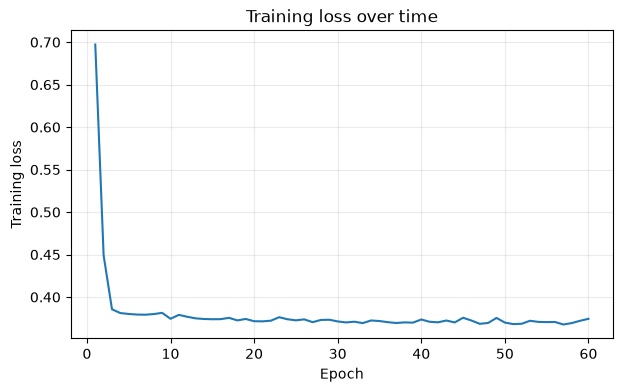

In [26]:
plt.figure(figsize=(7, 4))
plt.plot(history["epoch"], history["loss"])
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Training loss over time")
plt.grid(alpha=0.25)
plt.show()

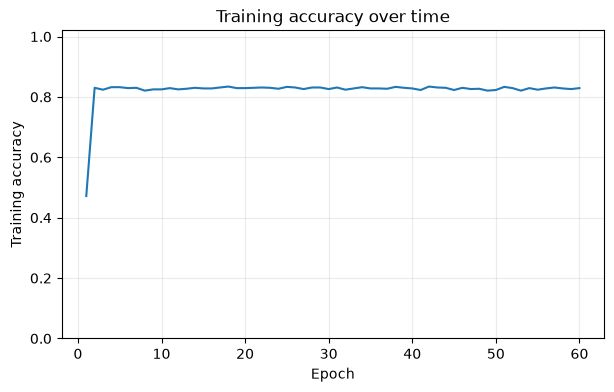

In [27]:
plt.figure(figsize=(7, 4))
plt.plot(history["epoch"], history["accuracy"])
plt.xlabel("Epoch")
plt.ylabel("Training accuracy")
plt.ylim(0, 1.02)
plt.title("Training accuracy over time")
plt.grid(alpha=0.25)
plt.show()

## 13. Evaluate on unseen test data

Training performance tells us how well the model fits examples it has already used for learning.

The test set asks a different question:

> **Can the trained model make useful predictions for examples that did not update its weights?**

For evaluation:

1. call `model.eval()`;
2. disable gradient tracking with `torch.inference_mode()`;
3. run the forward pass;
4. convert logits to probabilities;
5. apply a classification threshold.

In [28]:
def evaluate_binary_classifier(model, X_tensor, y_tensor, loss_fn, threshold=0.5):
    model.eval()

    with torch.inference_mode():
        logits = model(X_tensor.to(device))
        targets = y_tensor.to(device)
        loss = loss_fn(logits, targets).item()
        probabilities = torch.sigmoid(logits)
        predictions = (probabilities >= threshold).float()
        accuracy = (predictions == targets).float().mean().item()

    return {
        "loss": loss,
        "accuracy": accuracy,
        "logits": logits.cpu(),
        "probabilities": probabilities.cpu(),
        "predictions": predictions.cpu(),
    }


test_results = evaluate_binary_classifier(
    model,
    X_test_tensor,
    y_test_tensor,
    loss_fn,
)

print("Test loss:    {:.4f}".format(test_results["loss"]))
print("Test accuracy:{:.3f}".format(test_results["accuracy"]))

Test loss:    0.3958
Test accuracy:0.821


In [29]:
preview = pd.DataFrame({
    "attendance": X_test_raw[:12, 0],
    "study_hours": X_test_raw[:12, 1],
    "midterm_score": X_test_raw[:12, 2],
    "true_label": y_test[:12, 0].astype(int),
    "pass_probability": test_results["probabilities"][:12, 0].numpy(),
    "prediction": test_results["predictions"][:12, 0].numpy().astype(int),
})

preview.round(3)

,attendance,study_hours,midterm_score,true_label,pass_probability,prediction
0,75.706001,4.997,6.091,1,0.781,1
1,82.592003,2.091,6.290,1,0.928,1
2,93.103996,2.229,4.508,1,0.719,1
3,49.136002,0.666,3.369,0,0.014,0
4,93.161003,2.531,3.147,0,0.653,1
5,91.220001,4.942,7.768,1,0.995,1
6,46.058998,8.630,6.090,0,0.251,0
7,60.630001,0.953,6.215,0,0.270,0
8,46.370998,1.981,8.221,1,0.255,0
9,60.679001,6.487,7.568,0,0.765,1


## 14. Compare predictions before and after learning

Before training, the model's parameters were random.

After training, those parameters have been adjusted to reduce the loss on many examples.

The architecture did not change:

```text
3 -> 8 -> 4 -> 1
```

What changed were the **parameter values** inside the linear layers.

That distinction is fundamental:

> **architecture = structure**  
> **parameters = learned numbers inside that structure**

In [30]:
model.eval()
with torch.inference_mode():
    after_logits = model(first_X_batch[:5].to(device))
    after_probabilities = torch.sigmoid(after_logits)

comparison = pd.DataFrame({
    "true_label": first_y_batch[:5, 0].numpy().astype(int),
    "before_training_probability": sample_probabilities[:, 0].numpy(),
    "after_training_probability": after_probabilities[:, 0].cpu().numpy(),
})

comparison.round(3)

,true_label,before_training_probability,after_training_probability
0,1,0.393,0.921
1,0,0.386,0.413
2,1,0.393,0.698
3,0,0.372,0.042
4,1,0.393,0.735


## 15. Inference on a new student

Now we leave the training process.

Suppose a new student has:

```text
attendance = 82%
study hours = 6 hours/week
midterm score = 7.2 / 10
```

The inference pipeline must use the **same feature order and the same normalization statistics** used during training.

A common production bug is to train with one preprocessing pipeline and infer with another.

In [31]:
def predict_student(model, attendance, study_hours, midterm_score, threshold=0.5):
    raw = np.array([[attendance, study_hours, midterm_score]], dtype=np.float32)

    # Reuse TRAINING statistics. Do not recompute mean/std from the new sample.
    normalized = (raw - train_mean) / train_std
    x_new = torch.tensor(normalized, dtype=torch.float32).to(device)

    model.eval()
    with torch.inference_mode():
        logit = model(x_new)
        probability = torch.sigmoid(logit).item()

    prediction = int(probability >= threshold)
    label = "PASS" if prediction == 1 else "FAIL"

    return {
        "probability_of_pass": probability,
        "prediction": label,
        "threshold": threshold,
    }


new_student_result = predict_student(
    model,
    attendance=82,
    study_hours=6,
    midterm_score=7.2,
)

new_student_result

{'probability_of_pass': 0.9713895320892334,
 'prediction': 'PASS',
 'threshold': 0.5}

### Try several profiles

The model receives only numbers. It does not know what a "good student" means unless that pattern was represented in the training examples.

In [32]:
student_profiles = [
    {"name": "Student A", "attendance": 90, "study_hours": 8, "midterm_score": 8.0},
    {"name": "Student B", "attendance": 52, "study_hours": 2, "midterm_score": 3.5},
    {"name": "Student C", "attendance": 72, "study_hours": 5, "midterm_score": 5.5},
    {"name": "Student D", "attendance": 95, "study_hours": 1, "midterm_score": 4.0},
]

rows = []
for profile in student_profiles:
    result = predict_student(
        model,
        attendance=profile["attendance"],
        study_hours=profile["study_hours"],
        midterm_score=profile["midterm_score"],
    )
    rows.append({
        **profile,
        "pass_probability": result["probability_of_pass"],
        "prediction": result["prediction"],
    })

pd.DataFrame(rows).round(3)

,name,attendance,study_hours,midterm_score,pass_probability,prediction
0,Student A,90,8,8.0,0.997,PASS
1,Student B,52,2,3.5,0.028,FAIL
2,Student C,72,5,5.5,0.666,PASS
3,Student D,95,1,4.0,0.736,PASS


## 16. The complete pipeline in one picture

At this point, the whole workflow is:

```text
random synthetic data
        |
        v
features X + labels y
        |
        v
train/test split
        |
        v
normalize using TRAIN statistics
        |
        v
TensorDataset + DataLoader
        |
        v
MLP: 3 -> 8 -> 4 -> 1
        |
        v
forward pass -> logits
        |
        v
BCEWithLogitsLoss
        |
        v
backward() -> gradients
        |
        v
optimizer.step() -> new parameters
        |
        v
repeat for many batches / epochs
        |
        v
model.eval() + inference_mode()
        |
        v
new input -> probability -> PASS / FAIL
```

The most important idea is not the exact PyTorch syntax.

It is the separation of responsibilities:

| Object | Role |
|---|---|
| Tensor | Numerical data |
| Dataset | Stores samples and labels |
| DataLoader | Creates batches |
| Model | Maps inputs to logits |
| Loss function | Measures prediction error |
| Optimizer | Updates parameters using gradients |
| Training loop | Repeats learning steps |
| Inference code | Uses fixed learned parameters on new input |

# Exercises

Try these after the main notebook works. Change **one thing at a time** so you can connect a change to its effect.

## Exercise 1 — Read the architecture

Without running new code, answer:

1. Why does the first linear layer use `input_dim=3`?
2. Why does the final layer have one output instead of two?
3. Where are the nonlinear transformations?
4. How many trainable parameters does the model have? Verify your calculation against the notebook output.

## Exercise 2 — Change network capacity

Create a second model:

```text
3 -> 16 -> 8 -> 1
```

Tasks:

- count its parameters;
- train it for 60 epochs;
- compare its final training loss and test accuracy with the smaller model;
- explain why "more parameters" does not automatically mean "better".

## Exercise 3 — Experiment with learning rate

Try these learning rates separately:

```text
0.0001
0.01
0.1
```

Keep the architecture and dataset unchanged.

Questions:

- Which setting learns slowly?
- Does any setting become unstable?
- Why is it important to change only one variable during this comparison?

## Exercise 4 — What if we skip normalization?

Train the same architecture using the raw input values instead of standardized inputs.

Compare:

- the first few loss values;
- the shape of the loss curve;
- final test accuracy.

Do not conclude from one toy example that normalization is always mandatory. The goal is to observe that input scale can affect optimization.

## Exercise 5 — Inference experiment

Keep these fixed:

```text
attendance = 75%
study_hours = 5
```

Run inference for midterm scores:

```text
2, 4, 6, 8, 10
```

Create a small table containing:

- midterm score;
- probability of passing;
- predicted label.

Does the output change in the direction you expected?

## Exercise 6 — Threshold is not the same as training

Run inference on the same test probabilities using thresholds:

```text
0.3, 0.5, 0.7
```

Observe how many students are predicted as PASS.

The model parameters do not change when the threshold changes. Only the final decision rule changes.

## Optional starter code for Exercises 2 and 3

Uncomment and modify the values. The function reuses the same training pipeline so the comparison is easier to control.

In [ ]:
def run_experiment(hidden1=8, hidden2=4, learning_rate=0.01, epochs=60):
    torch.manual_seed(SEED)
    experiment_model = StudentPassMLP(
        input_dim=3,
        hidden1=hidden1,
        hidden2=hidden2,
    ).to(device)

    experiment_optimizer = torch.optim.Adam(
        experiment_model.parameters(),
        lr=learning_rate,
    )

    experiment_generator = torch.Generator().manual_seed(SEED)
    experiment_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        generator=experiment_generator,
    )

    experiment_history = train_model(
        experiment_model,
        experiment_loader,
        loss_fn,
        experiment_optimizer,
        epochs=epochs,
        log_every=epochs,  # compact output for experiments
    )

    experiment_test = evaluate_binary_classifier(
        experiment_model,
        X_test_tensor,
        y_test_tensor,
        loss_fn,
    )

    n_params = sum(p.numel() for p in experiment_model.parameters() if p.requires_grad)

    return {
        "model": experiment_model,
        "history": experiment_history,
        "parameter_count": n_params,
        "test_loss": experiment_test["loss"],
        "test_accuracy": experiment_test["accuracy"],
    }

# Example: uncomment to try a larger network.
# larger = run_experiment(hidden1=16, hidden2=8, learning_rate=0.01)
# print("Parameters:", larger["parameter_count"])
# print("Test accuracy:", round(larger["test_accuracy"], 3))

In [33]:
larger = run_experiment(hidden1=16, hidden2=8, learning_rate=0.01)
print("Parameters:", larger["parameter_count"])
print("Test accuracy:", round(larger["test_accuracy"], 3))
print("Final training loss:", larger["history"]["loss"][-1])
print("Test loss:", larger["test_loss"])

Epoch   1/60 | loss=0.5461 | train_accuracy=0.640
Epoch  60/60 | loss=0.3742 | train_accuracy=0.820
Parameters: 209
Test accuracy: 0.821
Final training loss: 0.3741927777727445
Test loss: 0.4144222140312195


In [34]:
larger = run_experiment(hidden1=16, hidden2=8, learning_rate=0.1)
print("Parameters:", larger["parameter_count"])
print("Test accuracy:", round(larger["test_accuracy"], 3))
print("Final training loss:", larger["history"]["loss"][-1])
print("Test loss:", larger["test_loss"])

Epoch   1/60 | loss=0.4818 | train_accuracy=0.744
Epoch  60/60 | loss=0.3997 | train_accuracy=0.814
Parameters: 209
Test accuracy: 0.817
Final training loss: 0.3996743157505989
Test loss: 0.47042638063430786


In [36]:
larger = run_experiment(hidden1=16, hidden2=8, learning_rate=0.0001)
print("Parameters:", larger["parameter_count"])
print("Test accuracy:", round(larger["test_accuracy"], 3))
print("Final training loss:", larger["history"]["loss"][-1])
print("Test loss:", larger["test_loss"])

Epoch   1/60 | loss=0.6592 | train_accuracy=0.640
Epoch  60/60 | loss=0.4973 | train_accuracy=0.640
Parameters: 209
Test accuracy: 0.621
Final training loss: 0.497282342116038
Test loss: 0.5162599682807922


In [37]:
small = run_experiment(
    hidden1=8,
    hidden2=4,
    learning_rate=0.01,
    epochs=60
)

large = run_experiment(
    hidden1=16,
    hidden2=8,
    learning_rate=0.01,
    epochs=60
)

print("Small model:")
print("Parameters:", small["parameter_count"])
print("Test accuracy:", round(small["test_accuracy"], 3))
print("Test loss:", round(small["test_loss"], 4))

print("\nLarge model:")
print("Parameters:", large["parameter_count"])
print("Test accuracy:", round(large["test_accuracy"], 3))
print("Test loss:", round(large["test_loss"], 4))

Epoch   1/60 | loss=0.6972 | train_accuracy=0.472
Epoch  60/60 | loss=0.3744 | train_accuracy=0.829
Epoch   1/60 | loss=0.5461 | train_accuracy=0.640
Epoch  60/60 | loss=0.3742 | train_accuracy=0.820
Small model:
Parameters: 73
Test accuracy: 0.821
Test loss: 0.3958

Large model:
Parameters: 209
Test accuracy: 0.821
Test loss: 0.4144


In [38]:
# EXERCISE 4: TRAIN WITHOUT NORMALIZATION

# 1. Train lại model với dữ liệu đã chuẩn hóa để làm baseline.
normalized_result = run_experiment(
    hidden1=8,
    hidden2=4,
    learning_rate=0.01,
    epochs=60,
)


# 2. Chuyển dữ liệu THÔ (chưa chuẩn hóa) thành tensor.
X_train_raw_tensor = torch.tensor(
    X_train_raw,
    dtype=torch.float32
)

X_test_raw_tensor = torch.tensor(
    X_test_raw,
    dtype=torch.float32
)

y_train_raw_tensor = torch.tensor(
    y_train,
    dtype=torch.float32
)

y_test_raw_tensor = torch.tensor(
    y_test,
    dtype=torch.float32
)


# 3. Tạo Dataset từ dữ liệu thô.
raw_train_dataset = TensorDataset(
    X_train_raw_tensor,
    y_train_raw_tensor
)

raw_test_dataset = TensorDataset(
    X_test_raw_tensor,
    y_test_raw_tensor
)


# 4. Tạo DataLoader cho dữ liệu thô.
raw_generator = torch.Generator().manual_seed(SEED)

raw_train_loader = DataLoader(
    raw_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=raw_generator,
)


# 5. Tạo model mới có cùng kiến trúc 3 → 8 → 4 → 1.
torch.manual_seed(SEED)

raw_model = StudentPassMLP(
    input_dim=3,
    hidden1=8,
    hidden2=4,
).to(device)


# 6. Dùng cùng loss và learning rate.
raw_loss_fn = nn.BCEWithLogitsLoss()

raw_optimizer = torch.optim.Adam(
    raw_model.parameters(),
    lr=0.01,
)


# 7. Huấn luyện model với dữ liệu chưa chuẩn hóa.
raw_history = train_model(
    raw_model,
    raw_train_loader,
    raw_loss_fn,
    raw_optimizer,
    epochs=60,
    log_every=10,
)


# 8. Đánh giá trên test set chưa chuẩn hóa.
raw_test_result = evaluate_binary_classifier(
    raw_model,
    X_test_raw_tensor,
    y_test_raw_tensor,
    raw_loss_fn,
)


# 9. Tạo bảng so sánh kết quả cuối.
comparison = pd.DataFrame({
    "Data": [
        "Normalized",
        "Not normalized",
    ],
    "Final train loss": [
        normalized_result["history"]["loss"][-1],
        raw_history["loss"][-1],
    ],
    "Final train accuracy": [
        normalized_result["history"]["accuracy"][-1],
        raw_history["accuracy"][-1],
    ],
    "Test loss": [
        normalized_result["test_loss"],
        raw_test_result["loss"],
    ],
    "Test accuracy": [
        normalized_result["test_accuracy"],
        raw_test_result["accuracy"],
    ],
})

display(comparison.round(4))

Epoch   1/60 | loss=0.6972 | train_accuracy=0.472
Epoch  60/60 | loss=0.3744 | train_accuracy=0.829
Epoch   1/60 | loss=0.6475 | train_accuracy=0.605
Epoch  10/60 | loss=0.5465 | train_accuracy=0.701
Epoch  20/60 | loss=0.4640 | train_accuracy=0.789
Epoch  30/60 | loss=0.4372 | train_accuracy=0.810
Epoch  40/60 | loss=0.4055 | train_accuracy=0.810
Epoch  50/60 | loss=0.4435 | train_accuracy=0.804
Epoch  60/60 | loss=0.3945 | train_accuracy=0.816


,Data,Final train loss,Final train accuracy,Test loss,Test accuracy
0,Normalized,0.3744,0.8292,0.3958,0.8208
1,Not normalized,0.3945,0.8156,0.4167,0.8083


In [39]:
first_epochs_comparison = pd.DataFrame({
    "Epoch": normalized_result["history"]["epoch"][:10],
    "Normalized loss": normalized_result["history"]["loss"][:10],
    "Not normalized loss": raw_history["loss"][:10],
})

display(first_epochs_comparison.round(4))

,Epoch,Normalized loss,Not normalized loss
0,1,0.6972,0.6475
1,2,0.4489,0.6014
2,3,0.3856,0.5990
3,4,0.3811,0.5913
4,5,0.3801,0.5836
5,6,0.3794,0.5797
6,7,0.3792,0.5704
7,8,0.3800,0.5577
8,9,0.3814,0.5481
9,10,0.3744,0.5465


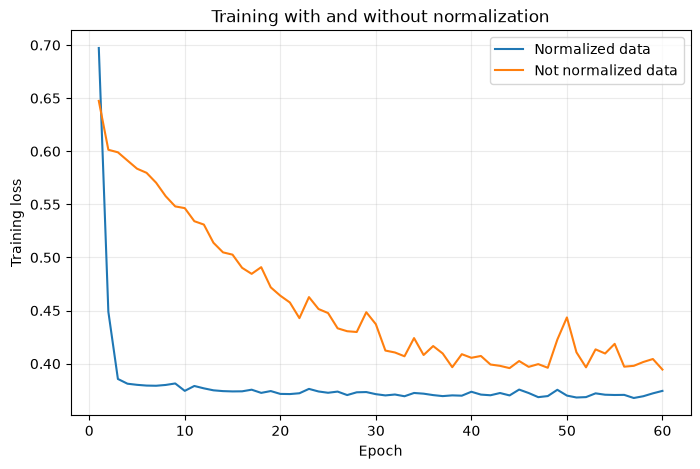

In [40]:
plt.figure(figsize=(8, 5))

plt.plot(
    normalized_result["history"]["epoch"],
    normalized_result["history"]["loss"],
    label="Normalized data",
)

plt.plot(
    raw_history["epoch"],
    raw_history["loss"],
    label="Not normalized data",
)

plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Training with and without normalization")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [41]:

# EXERCISE 5: INFERENCE EXPERIMENT

midterm_scores = [2, 4, 6, 8, 10]

# Sử dụng model đã huấn luyện với dữ liệu chuẩn hóa.
ex5_model = normalized_result["model"]

ex5_rows = []

for score in midterm_scores:
    result = predict_student(
        ex5_model,
        attendance=75,
        study_hours=5,
        midterm_score=score,
        threshold=0.5,
    )

    ex5_rows.append({
        "Attendance": 75,
        "Study hours": 5,
        "Midterm score": score,
        "Pass probability": result["probability_of_pass"],
        "Prediction": result["prediction"],
    })

ex5_results = pd.DataFrame(ex5_rows)

display(ex5_results.round({
    "Pass probability": 4
}))

,Attendance,Study hours,Midterm score,Pass probability,Prediction
0,75,5,2,0.3377,FAIL
1,75,5,4,0.5239,PASS
2,75,5,6,0.7518,PASS
3,75,5,8,0.9763,PASS
4,75,5,10,0.9987,PASS


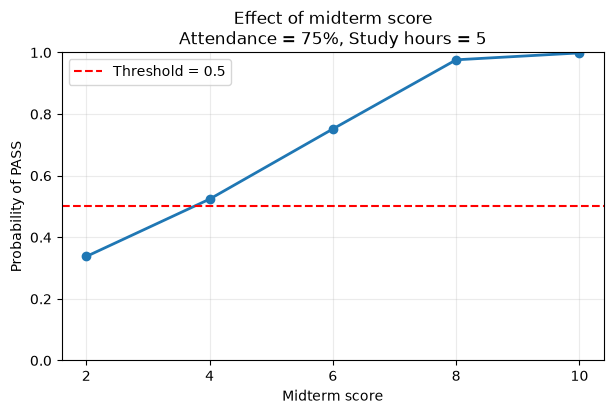

In [42]:
plt.figure(figsize=(7, 4))

plt.plot(
    ex5_results["Midterm score"],
    ex5_results["Pass probability"],
    marker="o",
    linewidth=2,
)

# Đường threshold dùng để quyết định PASS/FAIL.
plt.axhline(
    y=0.5,
    color="red",
    linestyle="--",
    label="Threshold = 0.5",
)

plt.xlabel("Midterm score")
plt.ylabel("Probability of PASS")
plt.title(
    "Effect of midterm score\n"
    "Attendance = 75%, Study hours = 5"
)
plt.xticks(midterm_scores)
plt.ylim(0, 1)
plt.grid(alpha=0.25)
plt.legend()
plt.show()

In [43]:
# EXERCISE 6: CHANGE CLASSIFICATION THRESHOLD

ex6_model = normalized_result["model"]
thresholds = [0.3, 0.5, 0.7]

# Tính xác suất đúng một lần.
# Khi thay threshold, model không được huấn luyện lại.
ex6_model.eval()

with torch.inference_mode():
    test_logits = ex6_model(X_test_tensor.to(device))
    test_probabilities = torch.sigmoid(test_logits).cpu()

test_targets = y_test_tensor.cpu()

ex6_rows = []

for threshold in thresholds:
    predictions = (
        test_probabilities >= threshold
    ).float()

    predicted_pass = int(predictions.sum().item())
    predicted_fail = len(predictions) - predicted_pass

    pass_percentage = (
        100 * predicted_pass / len(predictions)
    )

    accuracy = (
        predictions == test_targets
    ).float().mean().item()

    ex6_rows.append({
        "Threshold": threshold,
        "Predicted PASS": predicted_pass,
        "Predicted FAIL": predicted_fail,
        "PASS percentage": pass_percentage,
        "Test accuracy": accuracy,
    })

ex6_results = pd.DataFrame(ex6_rows)

display(ex6_results.round({
    "PASS percentage": 2,
    "Test accuracy": 4,
}))

,Threshold,Predicted PASS,Predicted FAIL,PASS percentage,Test accuracy
0,0.3,176,64,73.33,0.8042
1,0.5,156,84,65.00,0.8208
2,0.7,137,103,57.08,0.8250


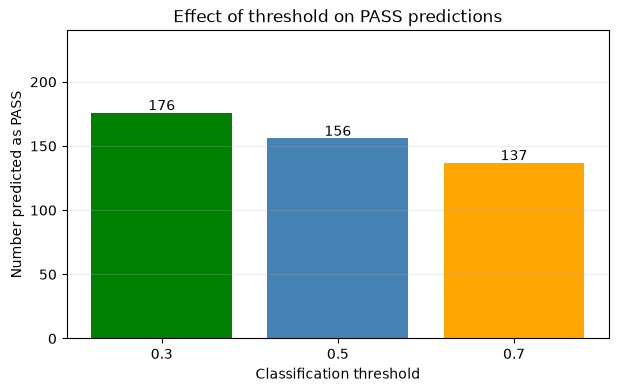

In [44]:
plt.figure(figsize=(7, 4))

bars = plt.bar(
    ex6_results["Threshold"].astype(str),
    ex6_results["Predicted PASS"],
    color=["green", "steelblue", "orange"],
)

plt.xlabel("Classification threshold")
plt.ylabel("Number predicted as PASS")
plt.title("Effect of threshold on PASS predictions")
plt.ylim(0, len(test_probabilities))
plt.grid(axis="y", alpha=0.25)

for bar, value in zip(
    bars,
    ex6_results["Predicted PASS"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        str(value),
        ha="center",
    )

plt.show()

## Final checks

You should now be able to explain the following sequence without looking at code:

1. turn examples into numerical features and labels;
2. split the data;
3. prepare inputs consistently;
4. create batches;
5. define a network architecture;
6. run a forward pass;
7. calculate loss;
8. backpropagate gradients;
9. update parameters;
10. repeat;
11. evaluate on unseen data;
12. use the trained model for inference.

### Five questions to check your understanding

1. What changes during training: the architecture or the parameter values?
2. Why do we call `optimizer.zero_grad()` before `backward()` in this loop?
3. Why does the model output a logit instead of directly returning the words `PASS` or `FAIL`?
4. Why must a new input use the same feature order and normalization as the training data?
5. What is the difference between `model.train()` and `model.eval()` at a high level?

If you can answer these clearly, you already understand the basic skeleton behind a large fraction of supervised deep-learning workflows.

## References consulted

This notebook follows stable beginner patterns from the official PyTorch documentation:

- **PyTorch — Learn the Basics:** tensors, datasets/data loaders, model building, autograd, optimization, save/load workflow.  
  https://docs.pytorch.org/tutorials/beginner/basics/intro.html
- **PyTorch — Quickstart:** `Dataset`, `DataLoader`, model construction, training and evaluation.  
  https://docs.pytorch.org/tutorials/beginner/basics/quickstart_tutorial.html
- **PyTorch — Training with PyTorch:** training loop, losses, optimizers, datasets and data loaders.  
  https://docs.pytorch.org/tutorials/beginner/introyt/trainingyt.html
- **PyTorch — Reproducibility:** random seeds and limits of exact reproducibility.  
  https://docs.pytorch.org/docs/stable/notes/randomness.html
- **Google Colab FAQ:** Colab supports uploading standard Jupyter `.ipynb` notebooks.  
  https://research.google.com/colaboratory/faq.html

The notebook intentionally avoids external datasets, Google Drive, GPU requirements, and unstable or experimental APIs so it can be uploaded to Colab and executed top-to-bottom with minimal setup.